# FloodGuard AI
## Next-season district flood-exposure regression
**M.Sohail — 16032**  |  **M.Umar — 16031**

Programming for Artificial Intelligence, Fall 2026, CUSIT.

This is a historical evaluation for Pakistan’s 160 districts in the source boundary snapshot, not a live warning service. AI-assisted code and documentation must be reviewed and understood by both students. See `docs/SUBMISSION_CHECKLIST.md` for remaining course requirements.

### 1. Reproducible setup
Extract the entire ZIP before opening this notebook. Install `requirements.txt` using Python 3.12. Run all cells in order. All model data are bundled; no internet is required to execute. Modular implementation is in `src/pipeline.py`.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT / 'src/pipeline.py').exists():
    raise FileNotFoundError('Open this notebook from the extracted FloodGuard_AI project.')
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.pipeline import load_data, audit, make_supervised, run, FEATURES
print('Project:', ROOT.name)

Project: FloodGuard_AI


### 2. Problem and success criteria
Proposed stakeholder: district disaster-preparedness analysts. Target: next season’s percentage of district area detected as flooded. Inputs: previous season’s flooded percentage, district area and province. Criteria fixed before fitting: final holdout MAE ≤ 5 percentage points; at least 10% lower MAE than persistence. These are classroom targets, not operational acceptance thresholds. Also compare a training-median predictor so weak criteria do not conceal a poor result.

In [2]:
raw_path = ROOT/'data/raw/District_Level_Data.csv'
data = load_data(raw_path)
audit_result = audit(data, raw_path)
display(data.head())
print(json.dumps(audit_result, indent=2))

{
  "rows": 640,
  "columns": 13,
  "districts": 160,
  "years": [
    2022,
    2023,
    2024,
    2025
  ],
  "missing": {
    "district_code": 0,
    "district_name": 0,
    "province_name": 0,
    "area_km2": 0,
    "flooded_km2": 0,
    "pct_flooded": 0,
    "year": 0,
    "gi_z": 0,
    "hotspot": 0,
    "lisa_quad": 0,
    "lisa_p": 0,
    "z_val": 0,
    "z_lag": 0
  },
  "duplicates": 0,
  "duplicate_keys": 0,
  "zero_target_count": 104,
  "year_summary": [
    {
      "year": 2022,
      "count": 160,
      "mean": 13.279832,
      "median": 1.657916,
      "max": 98.725922
    },
    {
      "year": 2023,
      "count": 160,
      "mean": 4.897276,
      "median": 0.445331,
      "max": 72.47023
    },
    {
      "year": 2024,
      "count": 160,
      "mean": 5.667129,
      "median": 0.821532,
      "max": 69.6901
    },
    {
      "year": 2025,
      "count": 160,
      "mean": 2.479137,
      "median": 0.285858,
      "max": 19.116478
    }
  ],
  "province_counts": {

,district_code,district_name,province_name,area_km2,flooded_km2,pct_flooded,year,gi_z,hotspot,lisa_quad,lisa_p,z_val,z_lag
0,PK101,Bagh,Azad Kashmir,697.150318,0.882081,0.126527,2022,-1.518462,Not Significant,Not Significant,0.159869,-0.565498,-0.724357
1,PK101,Bagh,Azad Kashmir,697.150318,0.000000,0.000000,2023,-1.158127,Not Significant,Not Significant,0.284568,-0.434868,-0.588694
2,PK101,Bagh,Azad Kashmir,697.150318,0.587542,0.084278,2024,-1.259662,Not Significant,Not Significant,0.244430,-0.473185,-0.632367
3,PK101,Bagh,Azad Kashmir,697.150318,0.000000,0.000000,2025,-1.530921,Not Significant,Not Significant,0.157349,-0.577807,-0.818760
4,PK102,Bhimber,Azad Kashmir,1218.879176,0.422603,0.034671,2022,0.280746,Not Significant,Not Significant,0.553343,-0.569447,0.347120


### 3. Source and dataset comparison
Primary source: Abdullah Umer (2026), Zenodo, DOI 10.5281/zenodo.20100773, CC BY 4.0, accessed 2026-11-24. The uploaded district CSV matches the published MD5. District table: 640 × 13; tehsil alternative: 2,308 × 11. Both represent the same four seasons, so the larger table does not add temporal depth. District data are chosen to match the proposed stakeholder and keep the exercise manageable. Original bytes and source dictionary are bundled.

In [3]:
alternative = pd.read_csv(ROOT/'data/raw/Tehsil_Level_Data.csv')
display(pd.DataFrame([{'candidate':'District','rows':len(data),'columns':data.shape[1],'units':data.district_code.nunique()}, {'candidate':'Tehsil','rows':len(alternative),'columns':alternative.shape[1],'units':alternative.tehsil_code.nunique()}]))
display(pd.read_csv(ROOT/'data/raw/Variable_Dictionary.csv', encoding='cp1252'))

,candidate,rows,columns,units
0,District,640,13,160
1,Tehsil,2308,11,577


,Variable,Description,Type / Values
0,province_name,Province or territory name.,"Character; one of: Punjab, Sindh, Khyber Pakht..."
1,district_name / tehsil_name,Official administrative unit name as provided ...,Character
2,district_code / tehsil_code,OCHA COD-AB administrative unit code used as t...,Character (e.g. PK101); unique per administrat...
3,area_km2,"Total administrative unit area in km², from pk...",Numeric
4,flooded_km2,VIIRS-detected flooded area within the adminis...,Numeric
5,pct_flooded,Flooded area expressed as a percentage of tota...,Numeric
6,year,Monsoon season year corresponding to the flood...,"Integer; one of: 2022, 2023, 2024, 2025"
7,gi_z,Getis-Ord Gi* z-score computed on pct_flooded ...,Numeric
8,hotspot,Gi* hotspot classification derived from gi_z.,"Character; one of: Hot Spot (99%), Hot Spot (9..."
9,lisa_quad,LISA quadrant classification derived from loca...,"Character; one of: High-High, Low-Low, High-Lo..."


### 4. Preparation and leakage control
Identifier whitespace is stripped; rows are sorted; invalid values and duplicate district-year keys are rejected. No observations are invented and no target values are imputed. The exact preceding year is joined by district code. First-year records have no lag and are excluded from supervised modelling. Same-year flooded area, percentages and spatial statistics are excluded from inputs because they contain the outcome. Test-year data are not used for EDA, feature selection or model selection.

In [4]:
supervised = make_supervised(data)
display(supervised.head())
display(supervised.groupby('year').size().rename('rows').to_frame())
print('Feature whitelist:', FEATURES)
assert len(supervised) == 480
assert set(FEATURES).isdisjoint({'pct_flooded','flooded_km2','gi_z','hotspot','lisa_quad','lisa_p','z_val','z_lag'})

Feature whitelist: ['prev_pct_flooded', 'area_km2', 'province_name']


,district_code,district_name,year,prev_pct_flooded,area_km2,province_name,pct_flooded
0,PK101,Bagh,2023,0.126527,697.150318,Azad Kashmir,0.000000
1,PK102,Bhimber,2023,0.034671,1218.879176,Azad Kashmir,0.023782
2,PK103,Jhelum Valley,2023,0.000000,684.545543,Azad Kashmir,0.000000
3,PK104,Haveli,2023,0.000000,553.493608,Azad Kashmir,0.000000
4,PK105,Kotli,2023,0.087360,1606.072213,Azad Kashmir,0.274955


,rows
year,
2023,160
2024,160
2025,160


### 5. Three experiments and final evaluation
Train on target year 2023; validate on 2024. E1 uses Ridge with lag only; E2 adds area and one-hot province; E3 changes to Random Forest. Select the smallest validation MAE, then refit the fixed configuration on 2023–2024 and evaluate 2025. Scaling, imputation and encoding are fitted within each training pipeline. Predictions are clipped to the physical 0–100% interval. No test-driven retuning is performed.

In [5]:
summary = run(ROOT)
display(pd.read_csv(ROOT/'reports/validation_metrics.csv'))
display(pd.read_csv(ROOT/'reports/test_metrics.csv'))

{
  "selected_model": "E3_Random_forest",
  "selection_rule": "2024 validation MAE, E1-E3 only",
  "train_rows": 160,
  "validation_rows": 160,
  "refit_rows": 320,
  "test_rows": 160,
  "test_metrics": {
    "mae": 2.7261614803225735,
    "mse": 36.19332289327143,
    "rmse": 6.016088670662312,
    "r2": -0.9784105960271336
  },
  "improvement_vs_persistence_pct": 37.875400199698376,
  "success_1_mae_le_5": true,
  "success_2_10pct_better_than_persistence": true,
  "python": "3.12.14",
  "sklearn": "1.8.0",
  "pandas": "2.2.3",
  "numpy": "2.3.5",
  "geographic_scope": "Future seasons for the same 160 districts; not unseen-district validation"
}


,experiment,mae,mse,rmse,r2,fit_seconds
0,E1_Ridge_lag,4.019778,82.906940,9.105325,0.400673,0.007968
1,E2_Ridge_geography,4.095802,84.553470,9.195296,0.388770,0.007821
2,E3_Random_forest,4.005892,91.390816,9.559854,0.339344,0.201314


,experiment,mae,mse,rmse,r2
0,E1_Ridge_lag,2.803609,28.696218,5.356885,-0.568602
1,E2_Ridge_geography,2.872260,30.214569,5.496778,-0.651598
2,E3_Random_forest,2.726161,36.193323,6.016089,-0.978411
3,B0_Training_median,2.473541,21.570479,4.644403,-0.179092
4,B1_Persistence,4.388216,121.970194,11.044012,-5.667172


### 6. Four EDA figures (development years only)
1. Distribution: low exposure dominates, so average accuracy-style descriptions would be misleading. MAE is reported in percentage points.
2. Seasons: different distributions caution against a random row split.
3. Provinces: aggregate exposure varies; these are unweighted means of district percentages, not province-area flood rates.
4. Lag relationship: a prior flood does not establish the next season’s intensity; weather and river inputs are absent.

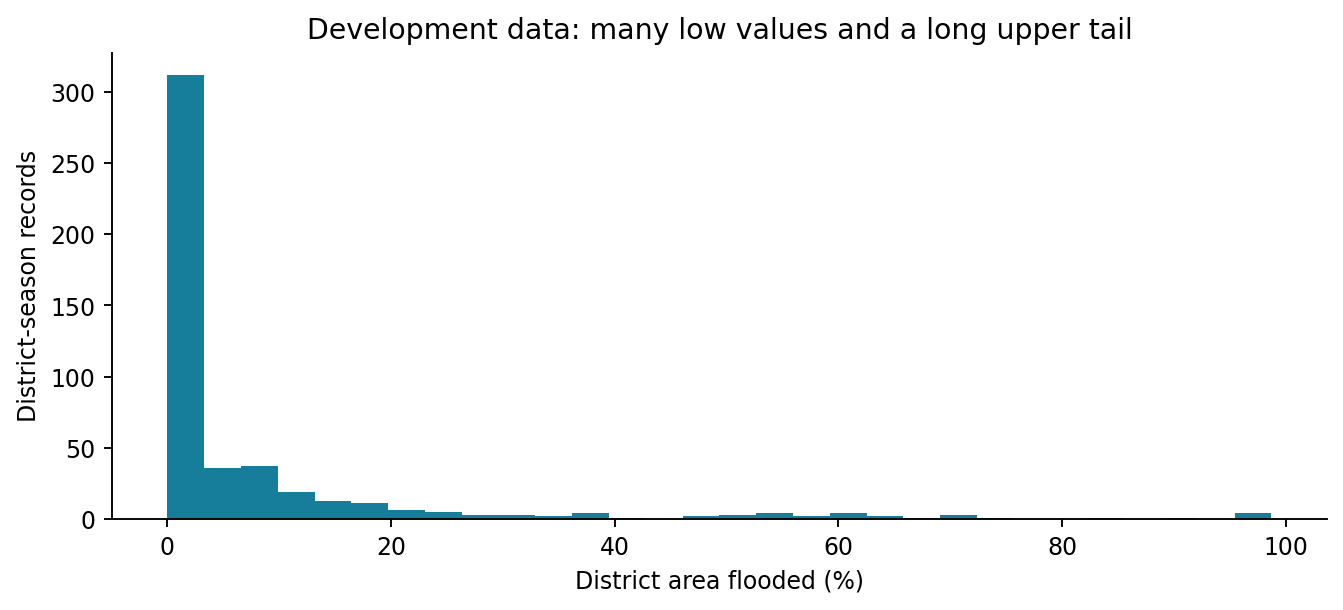

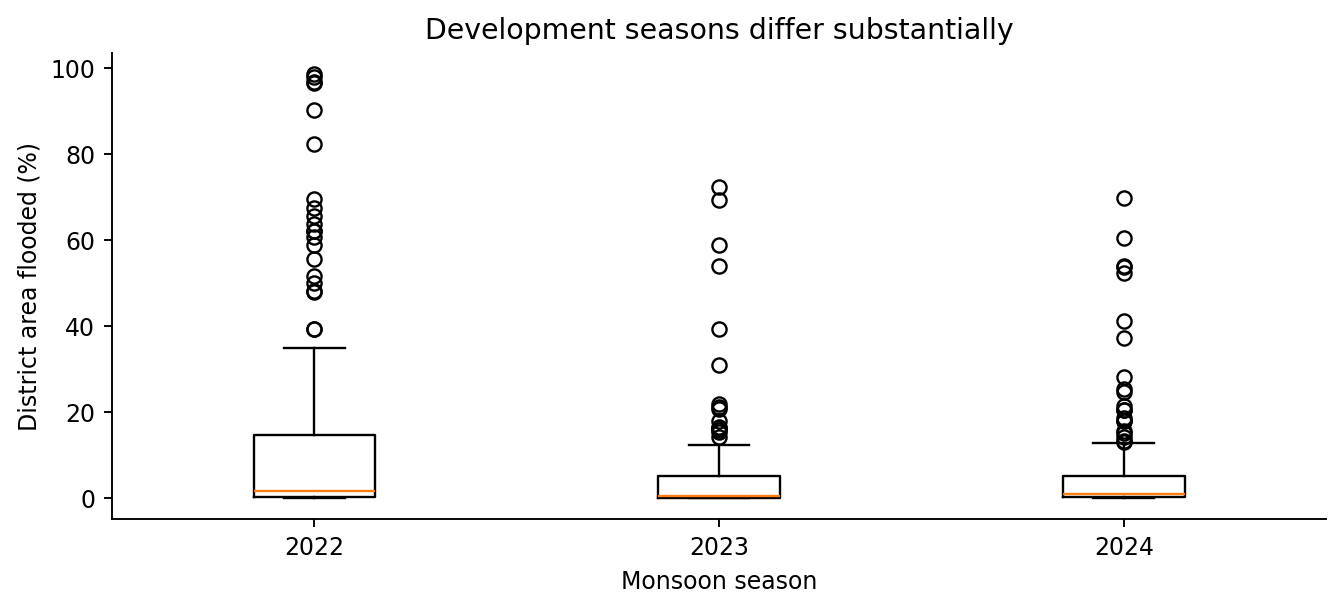

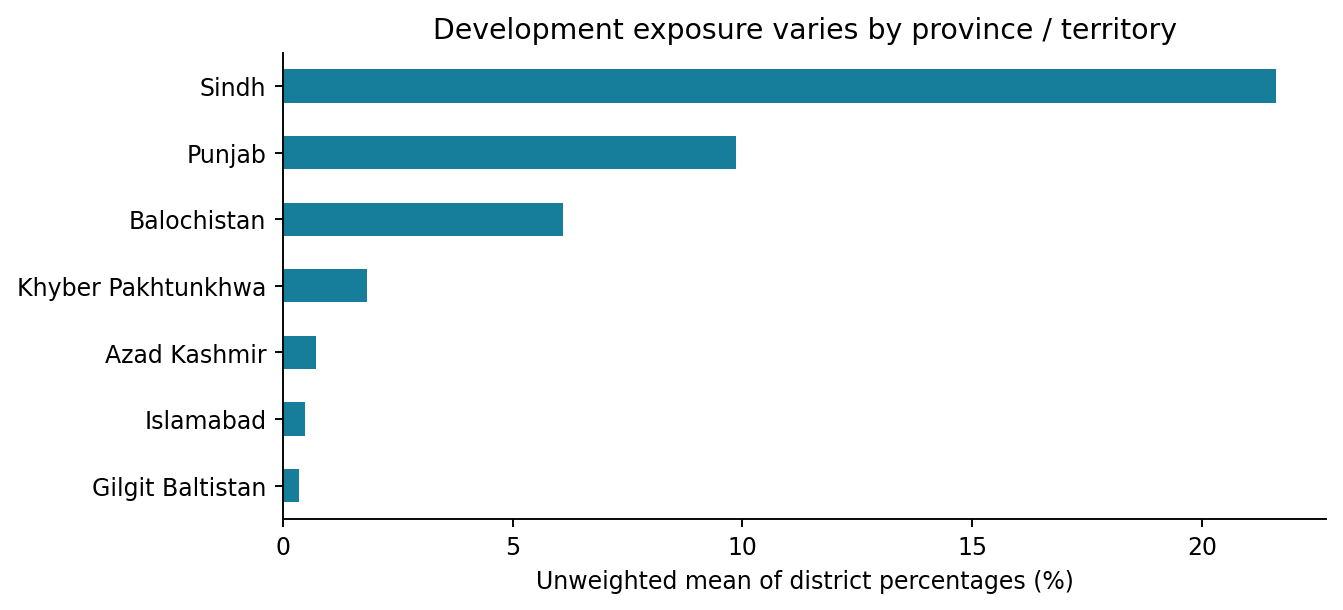

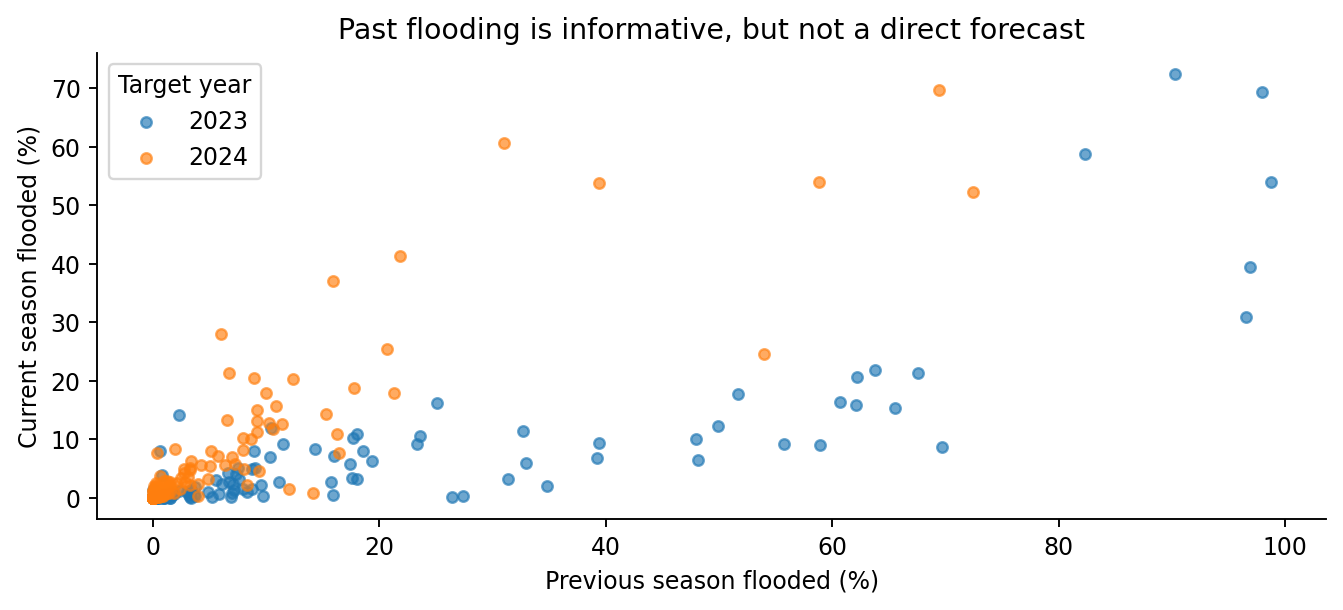

In [6]:
for name in ['01_distribution','02_year_comparison','03_province_exposure','04_lag_relationship']:
    display(Image(filename=str(ROOT/'reports/figures'/f'{name}.png')))

### 7. Holdout findings and error analysis
The validation-selected forest achieves MAE about 2.726 percentage points, but R² about −0.978. It beats persistence by about 37.9%, while the training-median model has lower MAE (about 2.474). Passing the two classroom criteria therefore does not establish useful forecasting skill. Province errors and the largest district errors expose weaknesses hidden by an average.

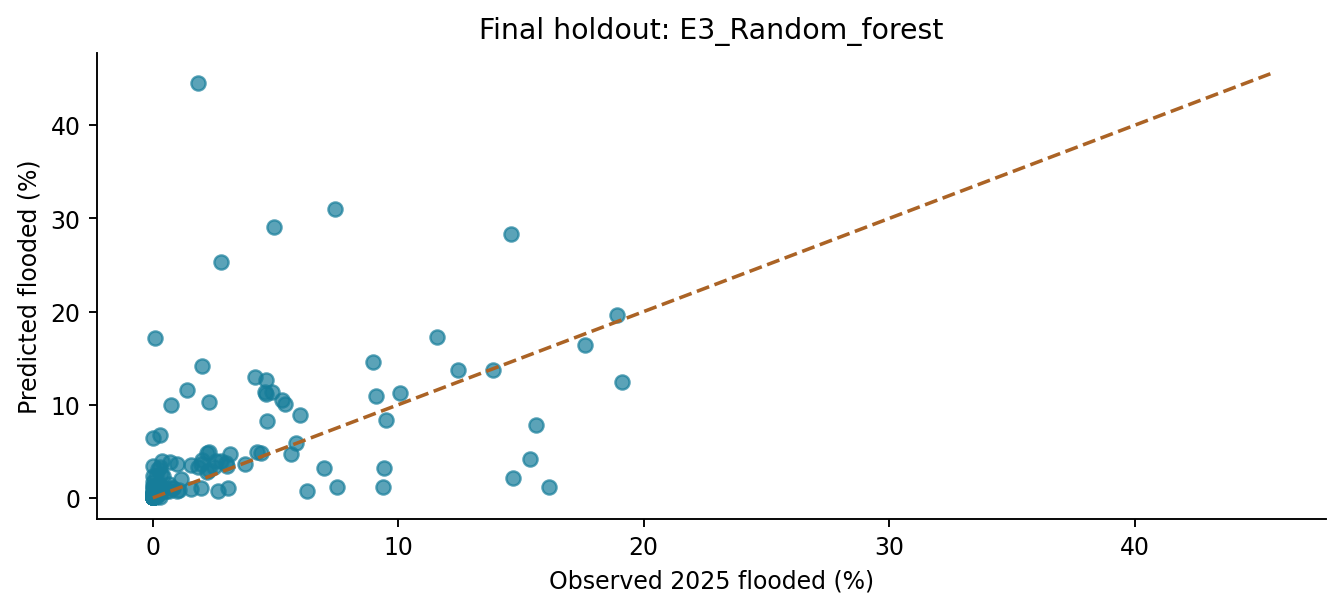

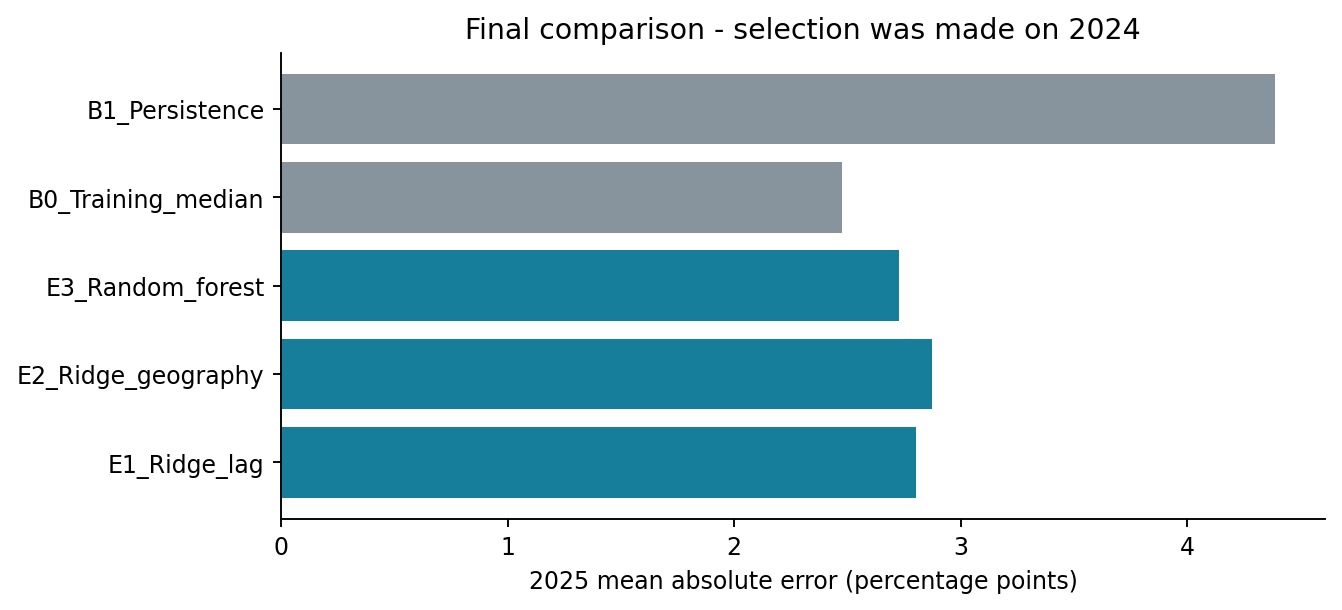

,province_name,n,mae,mean_actual,mean_predicted
0,Azad Kashmir,10.0,0.570572,0.915095,1.485666
1,Balochistan,35.0,1.842022,0.184314,2.012586
2,Gilgit Baltistan,14.0,0.666415,0.741802,1.258071
3,Islamabad,1.0,1.249074,0.191775,1.440848
4,Khyber Pakhtunkhwa,35.0,0.723001,0.615501,1.238430
5,Punjab,36.0,3.759892,6.480653,5.268924
6,Sindh,29.0,6.716184,3.987481,10.703665


,district_code,district_name,province_name,year,pct_flooded,E1_Ridge_lag,E2_Ridge_geography,E3_Random_forest,B0_Training_median,B1_Persistence,selected_prediction,absolute_error
0,PK707,Jacobabad,Sindh,2025,1.843185,33.351880,34.018347,44.529444,0.669072,69.690100,44.529444,42.686260
1,PK720,Shikarpur,Sindh,2025,4.924569,25.961009,27.093604,29.036244,0.669072,53.733443,29.036244,24.111675
2,PK713,Larkana,Sindh,2025,7.440828,29.135360,30.125515,31.000786,0.669072,60.586767,31.000786,23.559958
3,PK229,Sohbatpur,Balochistan,2025,2.784356,26.036458,24.771941,25.336637,0.669072,53.896336,25.336637,22.552281
4,PK207,Jaffarabad,Balochistan,2025,0.080607,12.485805,11.977942,17.144533,0.669072,24.640904,17.144533,17.063927


In [7]:
display(Image(filename=str(ROOT/'reports/figures/05_test_predictions.png')))
display(Image(filename=str(ROOT/'reports/figures/06_test_mae.png')))
display(pd.read_csv(ROOT/'reports/province_errors.csv'))
display(pd.read_csv(ROOT/'reports/largest_errors.csv').head(5))

### 8. Edge-case tests
Tests cover missing columns/files, duplicated keys, invalid percentages, zero areas, missing targets, empty data, exact lag joins, year gaps, unseen provinces and invalid prediction inputs. A target-mutation test checks that changing 2025 outcomes does not alter 2025 features. Test mutations are isolated fixtures, not fabricated project observations.

In [8]:
import subprocess
result = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'], cwd=ROOT, capture_output=True, text=True)
print(result.stdout + result.stderr)
(ROOT/'evidence/test_results.txt').write_text(result.stdout + result.stderr)
assert result.returncode == 0

test_duplicate_key (test_pipeline.PipelineTests.test_duplicate_key) ... ok
test_empty (test_pipeline.PipelineTests.test_empty) ... ok
test_exact_lag (test_pipeline.PipelineTests.test_exact_lag) ... ok
test_gap_not_bridged (test_pipeline.PipelineTests.test_gap_not_bridged) ... ok
test_invalid_percentage (test_pipeline.PipelineTests.test_invalid_percentage) ... ok
test_invalid_prediction_input (test_pipeline.PipelineTests.test_invalid_prediction_input) ... ok
test_missing_column (test_pipeline.PipelineTests.test_missing_column) ... ok
test_missing_file (test_pipeline.PipelineTests.test_missing_file) ... ok
test_nan_target (test_pipeline.PipelineTests.test_nan_target) ... ok
test_target_mutation_does_not_change_same_year_features (test_pipeline.PipelineTests.test_target_mutation_does_not_change_same_year_features) ... ok
test_unseen_province (test_pipeline.PipelineTests.test_unseen_province) ... ok
test_zero_area (test_pipeline.PipelineTests.test_zero_area) ... ok

-----------------------

### 9. Working demonstration
The saved model was fitted on targets through 2024. Demonstrate a real 2025 held-out district; do not present this as a current forecast. The command also displays the observed outcome so errors remain visible.

In [9]:
result = subprocess.run([sys.executable,'demo.py','--district','PK101'], cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0
(ROOT/'evidence/demo_output.txt').write_text(result.stdout)

Bagh (PK101), 2025 historical holdout
Predicted flooded area: 0.184% | Observed: 0.000%
Academic demonstration only; this is not a live forecast or evacuation recommendation.

Out[9]: 175


### 10. Recommendation and remaining work
Retain this as a reproducible research baseline. Add earlier seasons and weather/river predictors available before each forecast; use rolling temporal evaluation and independent geographic validation. Do not use it for evacuation, insurance, compensation or resource allocation. Review province errors and satellite detection limitations.

No Git repository is included at the user’s request. No student commits, meetings, approvals or contributions have been invented. The required 3–4-member team rule remains unresolved for the two supplied members. Suggested responsibilities and viva preparation are in `docs/`.

References: see `docs/REFERENCES.md` for seven sourced entries and access dates.